# data_api에서 있는 코드임

In [2]:
# Colab에서 Drive에 저장하려면 아래 두 줄도 실행하세요.
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [11]:
#import
import os
import re
import json
import time
import hashlib
import zipfile
import shutil
import sqlite3
from pathlib import Path
from datetime import datetime
from urllib.parse import unquote
import xml.etree.ElementTree as ET
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from IPython.display import display
from urllib.parse import quote, unquote

In [ ]:
# 서울 열린데이터광장에서 발급받은 인증키
SEOUL_API_KEY = ""

# 공공데이터포털 API에서 발급받은 인증키_ 역별 승하차인원
DATA_GO_KR_API_KEY = ""

# 전체 수집에 사용할 기간
START_DATE = "2021-01-01"
END_DATE = "2026-09-30"

# 상세 대여이력·고장신고의 첫 응답을 확인할 날짜
# 전체 수집 기간을 변경하는 값은 아닙니다.
CHECK_DATE = "2026-09-30"
CHECK_HOUR = 8

BASE_URL = "http://openapi.seoul.go.kr:8088"

print("대상: 서울 전체 대여소")
print("전체 수집 기간:", START_DATE, "~", END_DATE)
print("응답 확인 날짜:", CHECK_DATE)

대상: 서울 전체 대여소
전체 수집 기간: 2021-01-01 ~ 2026-09-30
응답 확인 날짜: 2026-09-30


In [4]:
# 이 함수는 첫 5행을 조회합니다.
# 전체 데이터를 받는 페이지 반복 코드는 다음 수집 단계에서 추가합니다.

def check_api(service, date_parameter=""):
    if SEOUL_API_KEY in ("", "본인_인증키"):
        raise ValueError("상단 SEOUL_API_KEY에 본인 인증키를 입력하세요.")

    url = (
        f"{BASE_URL}/{SEOUL_API_KEY}/json/"
        f"{service}/1/5/"
    )

    if date_parameter:
        url += date_parameter

    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        data = response.json()

    except (requests.RequestException, ValueError):
        # 인증키가 포함된 URL이 오류 출력에 노출되지 않도록 처리
        raise RuntimeError(
            f"{service}: 연결 또는 JSON 응답 오류입니다."
        ) from None

    # 서비스마다 다른 응답 이름을 찾아 처리
    result_data = next(
        (
            value
            for value in data.values()
            if isinstance(value, dict)
            and "row" in value
        ),
        None
    )

    result = (
        result_data.get("RESULT", {})
        if result_data is not None
        else data.get("RESULT", {})
    )

    code = result.get("CODE")
    message = result.get("MESSAGE")

    if code == "INFO-200":
        print(f"[{service}] 조회된 자료 없음: {date_parameter}")
        return pd.DataFrame()

    if code != "INFO-000" or result_data is None:
        raise RuntimeError(
            f"{service}: {code} / {message}"
        )

    df = pd.DataFrame(result_data["row"])

    print(f"\n서비스: {service}")
    print("응답 전체 건수:", result_data.get("list_total_count"))
    print("이번에 받은 행 수:", len(df))
    print("원본 컬럼:", df.columns.tolist())

    display(df)

    return df

In [5]:
def fetch_all_rows(service, date_parameter=""):
    # sample 키는 전체 수집에 사용할 수 없음
    if SEOUL_API_KEY.strip() in ("", "본인_인증키", "sample"):
        raise ValueError("전체 조회에는 본인 서울 API 인증키가 필요합니다.")

    page_size = 1000
    start = 1
    frames = []
    previous_rows = None

    while True:
        end = start + page_size - 1

        url = (
            f"{BASE_URL}/{SEOUL_API_KEY}/json/"
            f"{service}/{start}/{end}/"
        )

        if date_parameter:
            url += date_parameter

        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            data = response.json()

        except (requests.RequestException, ValueError):
            raise RuntimeError(
                f"{service}: {start}~{end}행 요청 실패"
            ) from None

        result_data = next(
            (
                value
                for value in data.values()
                if isinstance(value, dict) and "row" in value
            ),
            None
        )

        result = (
            result_data.get("RESULT", {})
            if result_data is not None
            else data.get("RESULT", {})
        )

        code = result.get("CODE")

        if code == "INFO-200":
            break

        if code != "INFO-000" or result_data is None:
            raise RuntimeError(
                f"{service}: {code} / {result.get('MESSAGE')}"
            )

        rows = result_data.get("row", [])

        if not rows:
            break

        # 페이지 조건이 무시되어 같은 응답이 반복되는 경우 확인
        if rows == previous_rows:
            raise RuntimeError(
                f"{service}: 이전 페이지와 동일한 응답입니다."
            )

        frames.append(pd.DataFrame(rows))

        print(
            f"{service}: {start}~{end} 요청 → "
            f"{len(rows):,}행 수신"
        )

        previous_rows = rows

        # 마지막 페이지
        if len(rows) < page_size:
            break

        start += page_size
        time.sleep(0.3)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)

In [6]:
# 원본 DataFrame을 각각 유지
df_station_raw = fetch_all_rows("tbCycleStationInfo")
df_master_raw = fetch_all_rows("bikeStationMaster")

print("대여소 정보:", df_station_raw.shape)
print("대여소 마스터:", df_master_raw.shape)

display(df_station_raw.head())
display(df_master_raw.head())

tbCycleStationInfo: 1~1000 요청 → 1,000행 수신
tbCycleStationInfo: 1001~2000 요청 → 1,000행 수신
tbCycleStationInfo: 2001~3000 요청 → 1,000행 수신
tbCycleStationInfo: 3001~4000 요청 → 244행 수신
bikeStationMaster: 1~1000 요청 → 1,000행 수신
bikeStationMaster: 1001~2000 요청 → 1,000행 수신
bikeStationMaster: 2001~3000 요청 → 1,000행 수신
bikeStationMaster: 3001~4000 요청 → 431행 수신
대여소 정보: (3244, 13)
대여소 마스터: (3431, 5)


,STA_LOC,RENT_ID,RENT_NO,RENT_NM,RENT_ID_NM,HOLD_NUM,STA_ADD1,STA_ADD2,STA_LAT,STA_LONG,START_INDEX,END_INDEX,RNUM
0,마포구,ST-10,00108,서교동 사거리,108. 서교동 사거리,12,서울특별시 마포구 양화로 93,427,37.55274582,126.91861725,0,0,1
1,광진구,ST-100,00503,더샵스타시티 C동 앞,503. 더샵스타시티 C동 앞,15,서울특별시 광진구 아차산로 262,더샵스타시티 C동 앞,37.53666687,127.07359314,0,0,2
2,양천구,ST-1000,00729,서부식자재마트 건너편,729. 서부식자재마트 건너편,10,서울특별시 양천구 신정동 236,서부식자재마트 건너편,37.51037979,126.86679840,0,0,3
3,양천구,ST-1002,00731,서울시 도로환경관리센터,731. 서울시 도로환경관리센터,10,서울특별시 양천구 목동동로 316-6,서울시 도로환경관리센터,37.52989960,126.87654114,0,0,4
4,양천구,ST-1003,00732,신월중학교,732. 신월중학교,10,서울특별시 양천구 화곡로 59,신월동 이마트,37.53955078,126.82830048,0,0,5


,RNTLS_ID,ADDR1,ADDR2,LAT,LOT
0,ST-10,서울특별시 마포구 양화로 93,427,37.552746,126.918617
1,ST-100,서울특별시 광진구 아차산로 262,더샵스타시티 C동 앞,37.536667,127.073593
2,ST-1000,서울특별시 양천구 신정동 236,서부식자재마트 건너편,37.510380,126.866798
3,ST-1001,서울특별시 양천구 남부순환로4길20,서서울호수공원,0.000000,0.000000
4,ST-1002,서울특별시 양천구 목동동로 316-6,서울시 도로환경관리센터,37.529900,126.876541


In [7]:
# 대여소 정보
df_station_info = df_station_raw[
    [
        "RENT_ID",
        "RENT_NO",
        "RENT_NM",
        "STA_LOC",
        "HOLD_NUM",
        "STA_ADD1",
        "STA_ADD2",
        "STA_LAT",
        "STA_LONG",
    ]
].rename(columns={
    "RENT_ID": "station_id",
    "RENT_NO": "station_no",
    "RENT_NM": "station_name",
    "STA_LOC": "station_group",
    "HOLD_NUM": "dock_count",
    "STA_ADD1": "address1_info",
    "STA_ADD2": "address2_info",
    "STA_LAT": "latitude_info",
    "STA_LONG": "longitude_info",
}).copy()

# 대여소 마스터
df_station_master = df_master_raw[
    ["RNTLS_ID", "ADDR1", "ADDR2", "LAT", "LOT"]
].rename(columns={
    "RNTLS_ID": "station_id",
    "ADDR1": "address1_master",
    "ADDR2": "address2_master",
    "LAT": "latitude_master",
    "LOT": "longitude_master",
}).copy()

# ID를 문자열로 통일
for df in [df_station_info, df_station_master]:
    df["station_id"] = (
        df["station_id"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    if df["station_id"].isna().any():
        raise ValueError("대여소ID가 없는 행을 먼저 확인해야 합니다.")

    duplicated = df[
        df["station_id"].duplicated(keep=False)
    ]

    if not duplicated.empty:
        display(duplicated)
        raise ValueError("대여소ID가 중복되어 병합을 중단합니다.")

# 대여소번호는 앞의 0을 보존
df_station_info["station_no"] = (
    df_station_info["station_no"].astype("string")
)

# 좌표·거치대 수를 숫자로 변경
for column in ["latitude_info", "longitude_info", "dock_count"]:
    df_station_info[column] = pd.to_numeric(
        df_station_info[column], errors="coerce"
    )

for column in ["latitude_master", "longitude_master"]:
    df_station_master[column] = pd.to_numeric(
        df_station_master[column], errors="coerce"
    )

In [8]:
df_station = df_station_info.merge(
    df_station_master,
    on="station_id",
    how="outer",
    validate="one_to_one",
    indicator="source_match",
)

# 출처별 좌표 유효 여부
for source in ["info", "master"]:
    lat = df_station[f"latitude_{source}"]
    lon = df_station[f"longitude_{source}"]

    df_station[f"coordinate_valid_{source}"] = (
        lat.between(-90, 90)
        & lon.between(-180, 180)
        & lat.ne(0)
        & lon.ne(0)
    )

# 유효하지 않은 좌표는 최종 좌표 후보에서 제외
latitude_info = df_station["latitude_info"].where(
    df_station["coordinate_valid_info"]
)
longitude_info = df_station["longitude_info"].where(
    df_station["coordinate_valid_info"]
)

latitude_master = df_station["latitude_master"].where(
    df_station["coordinate_valid_master"]
)
longitude_master = df_station["longitude_master"].where(
    df_station["coordinate_valid_master"]
)

# 임시 선택 규칙:
# 대여소 정보의 유효 좌표 우선, 없으면 마스터 좌표 사용
df_station["latitude"] = latitude_info.fillna(latitude_master)
df_station["longitude"] = longitude_info.fillna(longitude_master)

# 양쪽 좌표가 유효한 경우 차이 확인
both_valid = (
    df_station["coordinate_valid_info"]
    & df_station["coordinate_valid_master"]
)

df_station["latitude_difference"] = (
    df_station["latitude_info"]
    - df_station["latitude_master"]
).abs().where(both_valid)

df_station["longitude_difference"] = (
    df_station["longitude_info"]
    - df_station["longitude_master"]
).abs().where(both_valid)

# 소수점 표현 차이를 고려한 검토 기준. 필요하면 변경 가능.
COORDINATE_TOLERANCE = 0.00001

df_station["coordinate_conflict"] = (
    both_valid
    & (
        df_station["latitude_difference"].gt(COORDINATE_TOLERANCE)
        | df_station["longitude_difference"].gt(COORDINATE_TOLERANCE)
    )
)

# 충돌 좌표는 검토 전 최종값으로 확정하지 않음
df_station.loc[
    df_station["coordinate_conflict"],
    ["latitude", "longitude"]
] = float("nan")

# 현재 기준정보라는 점을 기록
df_station["reference_collected_at"] = pd.Timestamp.now(
    tz="Asia/Seoul"
)

print("병합한 대여소 수:", len(df_station))

print("\n출처 일치 상태")
display(df_station["source_match"].value_counts())

print("\n좌표가 충돌하는 대여소")
display(
    df_station.loc[
        df_station["coordinate_conflict"],
        [
            "station_id",
            "station_name",
            "latitude_info",
            "longitude_info",
            "latitude_master",
            "longitude_master",
        ]
    ].head(20)
)

print("\n최종 좌표를 확인하지 못한 대여소 수:")
print(df_station[["latitude", "longitude"]].isna().any(axis=1).sum())

display(df_station.head(10))

병합한 대여소 수: 3431

출처 일치 상태


,count
source_match,
both,3244
right_only,187
left_only,0



좌표가 충돌하는 대여소


,station_id,station_name,latitude_info,longitude_info,latitude_master,longitude_master



최종 좌표를 확인하지 못한 대여소 수:
77


,station_id,station_no,station_name,station_group,dock_count,address1_info,address2_info,latitude_info,longitude_info,address1_master,...,longitude_master,source_match,coordinate_valid_info,coordinate_valid_master,latitude,longitude,latitude_difference,longitude_difference,coordinate_conflict,reference_collected_at
0,ST-10,00108,서교동 사거리,마포구,12.0,서울특별시 마포구 양화로 93,427,37.552746,126.918617,서울특별시 마포구 양화로 93,...,126.918617,both,True,True,37.552746,126.918617,1.800000e-07,2.500000e-07,False,2026-10-07 10:08:45.668081+09:00
1,ST-100,00503,더샵스타시티 C동 앞,광진구,15.0,서울특별시 광진구 아차산로 262,더샵스타시티 C동 앞,37.536667,127.073593,서울특별시 광진구 아차산로 262,...,127.073593,both,True,True,37.536667,127.073593,1.300000e-07,1.400000e-07,False,2026-10-07 10:08:45.668081+09:00
2,ST-1000,00729,서부식자재마트 건너편,양천구,10.0,서울특별시 양천구 신정동 236,서부식자재마트 건너편,37.510380,126.866798,서울특별시 양천구 신정동 236,...,126.866798,both,True,True,37.510380,126.866798,2.100000e-07,4.000000e-07,False,2026-10-07 10:08:45.668081+09:00
3,ST-1001,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,서울특별시 양천구 남부순환로4길20,...,0.000000,right_only,False,False,NaN,NaN,NaN,NaN,False,2026-10-07 10:08:45.668081+09:00
4,ST-1002,00731,서울시 도로환경관리센터,양천구,10.0,서울특별시 양천구 목동동로 316-6,서울시 도로환경관리센터,37.529900,126.876541,서울특별시 양천구 목동동로 316-6,...,126.876541,both,True,True,37.529900,126.876541,4.000000e-07,1.400000e-07,False,2026-10-07 10:08:45.668081+09:00
5,ST-1003,00732,신월중학교,양천구,10.0,서울특별시 양천구 화곡로 59,신월동 이마트,37.539551,126.828300,서울특별시 양천구 화곡로 59,...,126.828300,both,True,True,37.539551,126.828300,2.200000e-07,4.800000e-07,False,2026-10-07 10:08:45.668081+09:00
6,ST-1004,00733,신정이펜하우스314동,양천구,10.0,서울특별시 양천구 신정이펜1로50,신정이펜하우스314동,37.514099,126.831001,서울특별시 양천구 신정이펜1로50,...,126.831001,both,True,True,37.514099,126.831001,1.200000e-07,2.800000e-07,False,2026-10-07 10:08:45.668081+09:00
7,ST-1005,00734,신트리공원 입구,양천구,10.0,서울특별시 양천구 신정동 310-8,신트리공원 입구,37.513950,126.856056,서울특별시 양천구 신정동 310-8,...,126.856056,both,True,True,37.513950,126.856056,3.500000e-07,2.100000e-07,False,2026-10-07 10:08:45.668081+09:00
8,ST-1006,00735,영도초등학교,양천구,10.0,서울특별시 양천구 목동중앙로 70 서울영도초등학교,,37.536377,126.871513,서울특별시 양천구 목동중앙로 70 서울영도초등학교,...,126.871513,both,True,True,37.536377,126.871513,5.000000e-08,3.700000e-07,False,2026-10-07 10:08:45.668081+09:00
9,ST-1007,00736,오솔길공원,양천구,10.0,서울특별시 양천구 남부순환로70길11-9,오솔길공원,37.522190,126.836700,서울특별시 양천구 남부순환로70길11-9,...,126.836700,both,True,True,37.522190,126.836700,9.000000e-08,4.400000e-07,False,2026-10-07 10:08:45.668081+09:00


# 지하철 관련정보


In [13]:
# =========================================================
# [확인 0] 공통 조회 함수
# - 서울 열린데이터광장 API를 소량(기본 5행) 호출해서
#   응답 상태 / 전체 건수 / 컬럼 / 샘플 행을 돌려줌
# - 오류가 나도 멈추지 않고 상태값으로 기록 → 여러 달을 한 번에 점검 가능
# - 인증키는 상단 SEOUL_API_KEY만 사용
# =========================================================
import time
import requests
import pandas as pd
from urllib.parse import quote
from IPython.display import display

BASE_URL = "http://openapi.seoul.go.kr:8088"

if SEOUL_API_KEY.strip() in ("", "본인_인증키", "sample"):
    raise ValueError("상단 SEOUL_API_KEY에 본인 인증키를 입력하세요.")


def probe(service, *params, start=1, end=5):
    """
    service : 서비스명 (예: 'CardSubwayTime')
    params  : 서비스명 뒤에 붙는 조건값 (예: '202101')
    반환    : 상태 정보 dict (+ 샘플 DataFrame)
    """
    # URL 경로 조각 만들기: 한글·공백 조건값도 안전하게 인코딩
    parts = [SEOUL_API_KEY.strip(), "json", service, str(start), str(end)]
    parts += [str(p) for p in params]
    url = f"{BASE_URL}/" + "/".join(quote(p, safe="") for p in parts) + "/"

    info = {
        "service": service,
        "params": "/".join(map(str, params)),
        "status": None,          # 자료있음 / 자료없음 / API오류 / 연결오류
        "code": None,            # INFO-000, INFO-200, ERROR-xxx 등
        "message": None,
        "total": None,           # list_total_count
        "columns": None,
        "sample": pd.DataFrame(),
    }

    # --- 호출 ---
    try:
        response = requests.get(url, timeout=(10, 60))
        response.raise_for_status()
        payload = response.json()
    except (requests.RequestException, ValueError):
        # 예외 메시지에 URL(인증키 포함)이 들어가므로 내용은 출력하지 않음
        info["status"] = "연결오류"
        return info

    # --- 응답 구조 해석 ---
    # 정상 응답: {서비스명: {"list_total_count", "RESULT", "row"}}
    # 오류 응답: {"RESULT": {...}} 처럼 최상위에 RESULT만 오는 경우가 있음
    box = next(
        (v for v in payload.values() if isinstance(v, dict) and "RESULT" in v),
        payload,
    )
    result = box.get("RESULT", {}) if isinstance(box, dict) else {}
    info["code"] = result.get("CODE")
    info["message"] = result.get("MESSAGE")

    if info["code"] == "INFO-000" and "row" in box:
        rows = box["row"]
        if isinstance(rows, dict):          # 1건이면 dict로 옴
            rows = [rows]
        df = pd.DataFrame(rows)
        info["status"] = "자료있음"
        info["total"] = int(box.get("list_total_count", len(df)))
        info["columns"] = df.columns.tolist()
        info["sample"] = df
    elif info["code"] == "INFO-200":
        info["status"] = "자료없음"
    else:
        # INFO-100: 인증키 오류 / ERROR-500 등: 서비스명·인자 오류 가능
        info["status"] = "API오류"

    return info


def show(info):
    # 확인 결과를 사람이 읽기 좋게 출력
    print(f"\n[{info['service']}] 조건={info['params'] or '없음'}")
    print("  상태:", info["status"], "/", info["code"], "/", info["message"])
    print("  전체 건수:", info["total"])
    print("  컬럼:", info["columns"])
    if not info["sample"].empty:
        display(info["sample"])

In [17]:
# =========================================================
# [지하철 A] 역 좌표 수집 — 서울시 역사마스터 정보 (subwayStationMaster)
#  A-1. 원본 수집·저장
#  A-2. 컬럼 표준화 + 좌표 검증 → subway_points (호선별 역 1행)
#  A-3. 환승역을 하나로 묶은 물리역 → subway_stations (위치 1곳 1행)
# =========================================================
import os
import re
import glob
import time
import numpy as np
import pandas as pd
from IPython.display import display

# 저장 위치 (이전 data.go.kr 시도분과 섞이지 않도록 새 폴더 사용)
SUBWAY_RAW_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/final_project/data/subway_card_raw"
)
SUBWAY_OUT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/final_project/data/subway_processed"
)
os.makedirs(SUBWAY_RAW_DIR, exist_ok=True)
os.makedirs(SUBWAY_OUT_DIR, exist_ok=True)


# ---------- 공통 함수 ----------
def pick_column(df, candidates, label, required=True):
    """후보 이름 중 실제 존재하는 컬럼명을 반환 (대소문자 무시)"""
    lookup = {str(c).strip().upper(): c for c in df.columns}
    for cand in candidates:
        if cand.upper() in lookup:
            return lookup[cand.upper()]
    if required:
        raise ValueError(
            f"[{label}] 컬럼을 찾지 못했습니다.\n"
            f"  후보: {candidates}\n  현재 컬럼: {df.columns.tolist()}"
        )
    return None


# 역명 표기가 출처마다 다를 때 수동으로 맞추는 표
# 예) {"총신대입구(이수)": "이수"} — 매칭 실패 목록을 보고 추가
MANUAL_NAME_MAP = {}


def normalize_name(name):
    """역명 정규화: 수동 매핑 → 괄호 내용 제거 → 공백 제거 → 끝의 '역' 제거"""
    s = str(name).strip()
    s = MANUAL_NAME_MAP.get(s, s)
    s = re.sub(r"\(.*?\)", "", s)      # 서울역(1) → 서울역
    s = re.sub(r"\s+", "", s)
    s = re.sub(r"역$", "", s)          # 서울역 → 서울 (역삼처럼 앞의 '역'은 유지)
    return s


def normalize_line(line):
    """호선 정규화: '01호선', '1호선', '1' → '1호선' / 그 외 노선명은 공백만 제거"""
    s = str(line).strip()
    m = re.fullmatch(r"0*(\d+)\s*(호선)?", s)
    return f"{int(m.group(1))}호선" if m else re.sub(r"\s+", "", s)


def haversine_m(lat1, lon1, lat2, lon2):
    """두 좌표 사이 직선거리(m). numpy 배열 브로드캐스팅 지원"""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371008.8 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


# ---------- A-1. 원본 수집·저장 ----------
df_subway_master_raw = fetch_all_rows("subwayStationMaster")
df_subway_master_raw.astype("string").to_parquet(
    os.path.join(SUBWAY_RAW_DIR, "subway_station_master_raw.parquet"),
    index=False,
)
print("역사마스터 원본:", df_subway_master_raw.shape)
print("원본 컬럼:", df_subway_master_raw.columns.tolist())


# ---------- A-2. 표준화 + 좌표 검증 ----------
raw = df_subway_master_raw
c_id   = pick_column(raw, ["BLDN_ID", "STATN_ID", "STATION_ID", "SBWY_STNS_ID"], "역ID")
c_name = pick_column(raw, ["BLDN_NM", "STATN_NM", "STATION_NM", "SBWY_STNS_NM"], "역명")
c_line = pick_column(raw, ["ROUTE", "LINE_NUM", "LINE_NM", "SBWY_ROUT_LN_NM"], "호선")
c_lat  = pick_column(raw, ["LAT", "LATITUDE"], "위도")
c_lon  = pick_column(raw, ["LOT", "LNG", "LON", "LONGITUDE"], "경도")

subway_points = pd.DataFrame({
    "subway_id":   raw[c_id].astype("string").str.strip(),
    "subway_name": raw[c_name].astype("string").str.strip(),
    "line":        raw[c_line].astype("string").str.strip(),
    "lat":         pd.to_numeric(raw[c_lat], errors="coerce"),
    "lon":         pd.to_numeric(raw[c_lon], errors="coerce"),
})

# 위도·경도가 뒤바뀌어 들어온 행 자동 교정 (위도 자리에 126~127이 있는 경우)
swapped = subway_points["lat"].between(124, 132) & subway_points["lon"].between(33, 39)
subway_points.loc[swapped, ["lat", "lon"]] = (
    subway_points.loc[swapped, ["lon", "lat"]].to_numpy()
)
print("위경도 뒤바뀜 교정:", int(swapped.sum()), "행")

# 수도권 범위 밖·결측·0 좌표는 오류 표로 분리
valid = subway_points["lat"].between(37.0, 38.2) & subway_points["lon"].between(126.0, 128.0)
subway_coord_errors = subway_points.loc[~valid].copy()
subway_points = (
    subway_points.loc[valid]
    .drop_duplicates(subset=["subway_id"])
    .reset_index(drop=True)
)

subway_points["name_key"] = subway_points["subway_name"].map(normalize_name)
subway_points["line_key"] = subway_points["line"].map(normalize_line)
print("유효 좌표 역(호선별):", len(subway_points), "/ 좌표 오류:", len(subway_coord_errors))


# ---------- A-3. 물리역(위치 1곳) 만들기 ----------
# 같은 역명 = 같은 위치로 보고 묶되, 좌표가 SAME_STATION_M 이상 벌어지면
# 이름만 같은 다른 역(예: 5호선 양평 vs 경의중앙선 양평)으로 보고 호선별로 분리
SAME_STATION_M = 700

subway_points["phys_key"] = subway_points["name_key"]
for name_key, g in subway_points.groupby("name_key"):
    spread = haversine_m(g["lat"], g["lon"], g["lat"].mean(), g["lon"].mean()).max()
    if spread > SAME_STATION_M:
        subway_points.loc[g.index, "phys_key"] = name_key + "_" + g["line_key"]

subway_stations = (
    subway_points.groupby("phys_key")
    .agg(
        subway_name=("subway_name", "first"),
        name_key=("name_key", "first"),
        lat=("lat", "mean"),
        lon=("lon", "mean"),
        lines=("line_key", lambda s: ", ".join(sorted(s.unique()))),
        n_lines=("line_key", "nunique"),
        subway_ids=("subway_id", lambda s: ", ".join(s)),
    )
    .reset_index()
)

print("물리역 수:", len(subway_stations),
      "/ 환승역(2개 호선 이상):", int((subway_stations["n_lines"] >= 2).sum()))
display(subway_stations.head())
if not subway_coord_errors.empty:
    print("\n좌표 오류 역:")
    display(subway_coord_errors)

subwayStationMaster: 1~1000 요청 → 784행 수신
역사마스터 원본: (784, 5)
원본 컬럼: ['BLDN_ID', 'BLDN_NM', 'ROUTE', 'LAT', 'LOT']
위경도 뒤바뀜 교정: 0 행
유효 좌표 역(호선별): 772 / 좌표 오류: 12
물리역 수: 643 / 환승역(2개 호선 이상): 109


,phys_key,subway_name,name_key,lat,lon,lines,n_lines,subway_ids
0,4.19민주묘지,4.19민주묘지,4.19민주묘지,37.649502,127.013684,우이신설선,1,4703
1,가능,가능,가능,37.748577,127.044213,경원선,1,1907
2,가락시장,가락시장,가락시장,37.492566,127.118077,"3호선, 8호선",2,"0340, 2818"
3,가산디지털단지,가산디지털단지,가산디지털단지,37.480959,126.882619,"7호선, 경부선",2,"1702, 2748"
4,가양,가양,가양,37.561391,126.854456,9호선,1,4107



좌표 오류 역:


,subway_id,subway_name,line,lat,lon
219,1401,봉명,장항선,36.801215,127.135763
220,1402,쌍용(나사렛대),장항선,36.793759,127.121400
221,1403,아산,장항선,36.792053,127.104361
222,1404,탕정,장항선,36.788660,127.084850
223,1405,배방,장항선,36.777629,127.052991
224,1407,온양온천,장항선,36.780483,127.003249
225,1408,신창(순천향대),장항선,36.769502,126.951108
270,1724,평택,경부선,36.990726,127.085159
271,1725,성환,경부선,36.916076,127.126964
272,1726,직산,경부선,36.870593,127.143904


## 승하차 인원수

In [19]:
# =========================================================
# [지하철 B] 승하차 원본 수집 — OA-12252 CardSubwayTime (교통카드 정산시스템)
#  - 조건값: 사용월(YYYYMM), 2021-01 ~ 2026-09 (점검 결과 69개월 모두 존재)
#  - 원본은 값을 바꾸지 않고 월별 parquet으로 저장
#  - 이미 받은 달은 건너뜀 → 중간에 끊겨도 다시 실행하면 이어서 수집
# =========================================================
SUBWAY_SERVICE = "CardSubwayTime"
months = pd.period_range(START_DATE, END_DATE, freq="M")

subway_collect_log = []

for month in months:
    ym = month.strftime("%Y%m")
    save_path = os.path.join(SUBWAY_RAW_DIR, f"subway_time_{ym}.parquet")

    if os.path.exists(save_path):
        print(f"{ym}: 이미 저장됨 → 건너뜀")
        continue

    df_month = fetch_all_rows(SUBWAY_SERVICE, ym)   # 1,000행 단위로 끝까지 수집

    if df_month.empty:
        # 빈 응답을 '승하차 0명'으로 확정하지 않고 기록만 남김
        status = "empty"
        print(f"{ym}: 빈 응답 → 저장하지 않음")
    else:
        # 문자열로 저장: 타입 혼합으로 인한 parquet 오류 방지, 원본값 보존
        df_month.astype("string").to_parquet(save_path, index=False)
        status = "saved"
        print(f"{ym}: {len(df_month):,}행 저장")

    subway_collect_log.append({
        "use_month": ym, "rows": len(df_month), "status": status,
        "collected_at": pd.Timestamp.now(tz="Asia/Seoul"),
    })
    time.sleep(0.2)

if subway_collect_log:
    log_path = os.path.join(SUBWAY_RAW_DIR, "collect_log.csv")
    pd.DataFrame(subway_collect_log).to_csv(
        log_path, mode="a", header=not os.path.exists(log_path),
        index=False, encoding="utf-8-sig",
    )

CardSubwayTime: 1~1000 요청 → 604행 수신
202101: 604행 저장
CardSubwayTime: 1~1000 요청 → 605행 수신
202102: 605행 저장
CardSubwayTime: 1~1000 요청 → 606행 수신
202103: 606행 저장
CardSubwayTime: 1~1000 요청 → 608행 수신
202104: 608행 저장
CardSubwayTime: 1~1000 요청 → 608행 수신
202105: 608행 저장
CardSubwayTime: 1~1000 요청 → 608행 수신
202106: 608행 저장
CardSubwayTime: 1~1000 요청 → 607행 수신
202107: 607행 저장
CardSubwayTime: 1~1000 요청 → 607행 수신
202108: 607행 저장
CardSubwayTime: 1~1000 요청 → 607행 수신
202109: 607행 저장
CardSubwayTime: 1~1000 요청 → 609행 수신
202110: 609행 저장
CardSubwayTime: 1~1000 요청 → 609행 수신
202111: 609행 저장
CardSubwayTime: 1~1000 요청 → 609행 수신
202112: 609행 저장
CardSubwayTime: 1~1000 요청 → 610행 수신
202201: 610행 저장
CardSubwayTime: 1~1000 요청 → 608행 수신
202202: 608행 저장
CardSubwayTime: 1~1000 요청 → 609행 수신
202203: 609행 저장
CardSubwayTime: 1~1000 요청 → 608행 수신
202204: 608행 저장
CardSubwayTime: 1~1000 요청 → 615행 수신
202205: 615행 저장
CardSubwayTime: 1~1000 요청 → 615행 수신
202206: 615행 저장
CardSubwayTime: 1~1000 요청 → 615행 수신
202207: 615행 저장
CardSubwayTi

In [20]:
# =========================================================
# [지하철 C] 원본 합치기 + 중복 확인·정리
#  C-1. 월별 원본 연결 (출처 파일명 기록)
#  C-2. 핵심 컬럼 탐지 (사용월·호선·역명·작업일자·시간대 컬럼)
#  C-3. 같은 (월, 호선, 역) 중복 확인 — 202607처럼 두 번 적재된 달 정리
#  ※ 시간대 컬럼을 긴 형식으로 바꾸는 작업은 이후 전처리 단계에서 진행
# =========================================================
# ---------- C-1 ----------
subway_files = sorted(glob.glob(os.path.join(SUBWAY_RAW_DIR, "subway_time_*.parquet")))
frames = []
for f in subway_files:
    d = pd.read_parquet(f)
    d["source_file"] = os.path.basename(f)
    frames.append(d)
df_subway_time_raw = pd.concat(frames, ignore_index=True)
print("파일 수:", len(subway_files), "/ 전체 행:", f"{len(df_subway_time_raw):,}")
print("원본 컬럼:", df_subway_time_raw.columns.tolist())

# ---------- C-2 ----------
t = df_subway_time_raw
c_month = pick_column(t, ["USE_MM", "USE_MON", "USE_YM", "USE_YYMM"], "사용월")
c_tline = pick_column(t, ["SBWY_ROUT_LN_NM", "LINE_NUM", "LINE_NM"], "호선")
c_tsta  = pick_column(t, ["STTN", "SBWY_STNS_NM", "SUB_STA_NM", "STTN_NM", "STATION_NM"], "역명")
c_job   = pick_column(t, ["JOB_YMD", "WORK_DT", "REG_YMD", "CRTR_YMD"], "작업일자", required=False)

# 시간대 컬럼: 'HR_4_GET_ON_NOPE'형 또는 '04시-05시 승차인원'형 등
hour_cols = [
    c for c in t.columns
    if re.search(r"HR_\d+|\d+\s*시|GET_O(N|FF)|RIDE|ALIGHT", str(c), re.IGNORECASE)
]
print(f"\n탐지 결과: 사용월={c_month}, 호선={c_tline}, 역명={c_tsta}, 작업일자={c_job}")
print("시간대 컬럼 수:", len(hour_cols), "예시:", hour_cols[:4])

# ---------- C-3 ----------
key = [c_month, c_tline, c_tsta]
dup_mask = t.duplicated(subset=key, keep=False)
print("\n(월, 호선, 역) 중복 행:", int(dup_mask.sum()))
if dup_mask.any():
    display(t.loc[dup_mask].groupby(c_month).size().to_frame("중복 행 수"))

    # 중복이 값까지 완전히 같은 복사본인지 확인
    value_cols = [c for c in t.columns if c != "source_file"]
    exact_dup = t.duplicated(subset=value_cols, keep=False) & dup_mask
    print("그중 값까지 동일한 행:", int(exact_dup.sum()),
          "/ 값이 다른 중복 행:", int((dup_mask & ~exact_dup).sum()))

if c_job:
    # 작업일자가 있으면 가장 최근에 적재된 행을 남김 (정정 재적재로 판단)
    df_subway_time = (
        t.sort_values(c_job, ascending=False)
         .drop_duplicates(subset=key, keep="first")
    )
else:
    # 작업일자가 없으면 완전 동일 행만 제거하고, 남은 중복은 경고 후 첫 행 유지
    df_subway_time = t.drop_duplicates(subset=[c for c in t.columns if c != "source_file"])
    remain = df_subway_time.duplicated(subset=key).sum()
    if remain:
        print(f"※ 값이 다른 중복 {remain}행이 남아 첫 행을 유지합니다. 원본 확인 필요.")
    df_subway_time = df_subway_time.drop_duplicates(subset=key, keep="first")

df_subway_time = df_subway_time.sort_values(key).reset_index(drop=True)
print("\n정리 전:", f"{len(t):,}", "→ 정리 후:", f"{len(df_subway_time):,}")
display(df_subway_time.groupby(c_month).size().describe().to_frame("월별 행 수"))

파일 수: 69 / 전체 행: 43,760
원본 컬럼: ['USE_MM', 'SBWY_ROUT_LN_NM', 'STTN', 'HR_4_GET_ON_NOPE', 'HR_4_GET_OFF_NOPE', 'HR_5_GET_ON_NOPE', 'HR_5_GET_OFF_NOPE', 'HR_6_GET_ON_NOPE', 'HR_6_GET_OFF_NOPE', 'HR_7_GET_ON_NOPE', 'HR_7_GET_OFF_NOPE', 'HR_8_GET_ON_NOPE', 'HR_8_GET_OFF_NOPE', 'HR_9_GET_ON_NOPE', 'HR_9_GET_OFF_NOPE', 'HR_10_GET_ON_NOPE', 'HR_10_GET_OFF_NOPE', 'HR_11_GET_ON_NOPE', 'HR_11_GET_OFF_NOPE', 'HR_12_GET_ON_NOPE', 'HR_12_GET_OFF_NOPE', 'HR_13_GET_ON_NOPE', 'HR_13_GET_OFF_NOPE', 'HR_14_GET_ON_NOPE', 'HR_14_GET_OFF_NOPE', 'HR_15_GET_ON_NOPE', 'HR_15_GET_OFF_NOPE', 'HR_16_GET_ON_NOPE', 'HR_16_GET_OFF_NOPE', 'HR_17_GET_ON_NOPE', 'HR_17_GET_OFF_NOPE', 'HR_18_GET_ON_NOPE', 'HR_18_GET_OFF_NOPE', 'HR_19_GET_ON_NOPE', 'HR_19_GET_OFF_NOPE', 'HR_20_GET_ON_NOPE', 'HR_20_GET_OFF_NOPE', 'HR_21_GET_ON_NOPE', 'HR_21_GET_OFF_NOPE', 'HR_22_GET_ON_NOPE', 'HR_22_GET_OFF_NOPE', 'HR_23_GET_ON_NOPE', 'HR_23_GET_OFF_NOPE', 'HR_0_GET_ON_NOPE', 'HR_0_GET_OFF_NOPE', 'HR_1_GET_ON_NOPE', 'HR_1_GET_OFF_NOPE', '

,중복 행 수
USE_MM,
202603,1240
202607,1242


그중 값까지 동일한 행: 2482 / 값이 다른 중복 행: 0

정리 전: 43,760 → 정리 후: 42,519


,월별 행 수
count,69.000000
mean,616.217391
std,5.562134
min,604.000000
25%,613.000000
50%,617.000000
75%,621.000000
max,623.000000


In [21]:
# =========================================================
# [지하철 D] 승하차 데이터의 역(역명+호선) ↔ 역 좌표(물리역) 매칭
#  - 승하차 데이터에는 좌표·역ID가 없으므로 정규화한 역명으로 연결
#  - 1차: 역명+호선 일치 / 2차: 역명만 일치(그 역명이 물리역 1곳일 때만)
#  - 실패 목록은 MANUAL_NAME_MAP에 추가한 뒤 [지하철 A]부터 다시 실행
# =========================================================
ride_sta = (
    df_subway_time[[c_tline, c_tsta]]
    .drop_duplicates()
    .rename(columns={c_tline: "ride_line", c_tsta: "ride_station"})
    .reset_index(drop=True)
)
ride_sta["name_key"] = ride_sta["ride_station"].map(normalize_name)
ride_sta["line_key"] = ride_sta["ride_line"].map(normalize_line)

# 1차: 역명 + 호선
point_keys = subway_points[["name_key", "line_key", "phys_key"]].drop_duplicates(["name_key", "line_key"])
subway_station_match = ride_sta.merge(point_keys, on=["name_key", "line_key"], how="left")
subway_station_match["match_method"] = np.where(
    subway_station_match["phys_key"].notna(), "역명+호선", None
)

# 2차: 역명만 (동명이역이 아닌 경우에만 허용)
phys_per_name = subway_points.groupby("name_key")["phys_key"].nunique()
single_names = phys_per_name[phys_per_name == 1].index
name_to_phys = (
    subway_points[subway_points["name_key"].isin(single_names)]
    .drop_duplicates("name_key").set_index("name_key")["phys_key"]
)
need = subway_station_match["phys_key"].isna()
subway_station_match.loc[need, "phys_key"] = subway_station_match.loc[need, "name_key"].map(name_to_phys)
subway_station_match.loc[need & subway_station_match["phys_key"].notna(), "match_method"] = "역명만"

subway_unmatched = subway_station_match[subway_station_match["phys_key"].isna()].copy()

print("승하차 데이터 역(호선별):", len(subway_station_match))
display(subway_station_match["match_method"].value_counts(dropna=False).to_frame("역 수"))
print("\n매칭 실패 역 (MANUAL_NAME_MAP 추가 대상):")
display(subway_unmatched if not subway_unmatched.empty else "없음")

승하차 데이터 역(호선별): 640


,역 수
match_method,
역명+호선,579
역명만,43
None,18



매칭 실패 역 (MANUAL_NAME_MAP 추가 대상):


,ride_line,ride_station,name_key,line_key,phys_key,match_method
97,4호선,당고개,당고개,4호선,NaN,None
341,경부선,두정,두정,경부선,NaN,None
349,경부선,성환,성환,경부선,NaN,None
363,경부선,직산,직산,경부선,NaN,None
365,경부선,천안,천안,경부선,NaN,None
366,경부선,평택,평택,경부선,NaN,None
415,경의선,운정,운정,경의선,NaN,None
577,장항선,배방,배방,장항선,NaN,None
578,장항선,봉명,봉명,장항선,NaN,None
579,장항선,신창(순천향대),신창,장항선,NaN,None


In [22]:
# =========================================================
# [지하철 E] 따릉이 대여소 ↔ 물리역 거리 연결 (지도 대신 데이터프레임으로 보관)
#  E-1. 좌표 확인된 대여소만 사용 (df_station의 latitude/longitude)
#  E-2. 대여소 × 역 직선거리 행렬 계산 (numpy 브로드캐스팅)
#  E-3. bike_nearest_subway : 대여소별 가장 가까운 역 1곳 (반경 무관, 전체 대여소)
#  E-4. station_subway_link : 반경 500m 안의 모든 (대여소, 역) 쌍 — 다대다
# =========================================================
MAX_LINK_RADIUS_M = 500     # 연결 최대 반경
NEAR_RADIUS_M = 300         # 근접 구간 경계

# ---------- E-1 ----------
bike = (
    df_station.loc[
        df_station[["latitude", "longitude"]].notna().all(axis=1),
        ["station_id", "station_name", "latitude", "longitude"],
    ]
    .reset_index(drop=True)
)
print("좌표 확인된 대여소:", len(bike), "/ 제외:", len(df_station) - len(bike))

# ---------- E-2 ----------
# 결과 shape = (대여소 수, 물리역 수)
dist = haversine_m(
    bike["latitude"].to_numpy()[:, None],
    bike["longitude"].to_numpy()[:, None],
    subway_stations["lat"].to_numpy()[None, :],
    subway_stations["lon"].to_numpy()[None, :],
)

# ---------- E-3 ----------
nearest_idx = dist.argmin(axis=1)
bike_nearest_subway = bike.assign(
    nearest_phys_key=subway_stations["phys_key"].to_numpy()[nearest_idx],
    nearest_subway_name=subway_stations["subway_name"].to_numpy()[nearest_idx],
    nearest_distance_m=dist[np.arange(len(bike)), nearest_idx].round(1),
)

# ---------- E-4 ----------
bi, si = np.where(dist <= MAX_LINK_RADIUS_M)
station_subway_link = pd.DataFrame({
    "station_id":   bike["station_id"].to_numpy()[bi],
    "station_name": bike["station_name"].to_numpy()[bi],
    "phys_key":     subway_stations["phys_key"].to_numpy()[si],
    "subway_name":  subway_stations["subway_name"].to_numpy()[si],
    "lines":        subway_stations["lines"].to_numpy()[si],
    "distance_m":   dist[bi, si].round(1),
})
station_subway_link["radius_band"] = np.where(
    station_subway_link["distance_m"] <= NEAR_RADIUS_M,
    f"0-{NEAR_RADIUS_M}m", f"{NEAR_RADIUS_M}-{MAX_LINK_RADIUS_M}m",
)
# 한 대여소가 여러 역 반경에 걸칠 때 가까운 순서
station_subway_link["rank_in_station"] = (
    station_subway_link.groupby("station_id")["distance_m"].rank(method="first").astype(int)
)
station_subway_link["is_nearest"] = station_subway_link["rank_in_station"].eq(1)
station_subway_link["radius_m"] = MAX_LINK_RADIUS_M
station_subway_link = station_subway_link.sort_values(["phys_key", "distance_m"]).reset_index(drop=True)

# ---------- 요약 ----------
n_bike = len(bike)
for r in (NEAR_RADIUS_M, MAX_LINK_RADIUS_M):
    share = (bike_nearest_subway["nearest_distance_m"] <= r).mean()
    print(f"역 {r}m 안에 있는 대여소: {share:.1%}")

per_subway = station_subway_link.groupby("phys_key").size()
print("근처 대여소가 있는 역:", per_subway.size, "/", len(subway_stations))
print("역당 근처 대여소 수:")
display(per_subway.describe().to_frame(f"{MAX_LINK_RADIUS_M}m 안 대여소 수"))
display(station_subway_link.head(10))

# ---------- 저장 (다음 단계 전처리·분석에서 재사용) ----------
for name, df_out in {
    "subway_points": subway_points,
    "subway_stations": subway_stations,
    "subway_station_match": subway_station_match,
    "station_subway_link": station_subway_link,
    "bike_nearest_subway": bike_nearest_subway,
}.items():
    df_out.to_parquet(os.path.join(SUBWAY_OUT_DIR, f"{name}.parquet"), index=False)
print("\n저장 완료:", SUBWAY_OUT_DIR)

좌표 확인된 대여소: 3354 / 제외: 77
역 300m 안에 있는 대여소: 34.1%
역 500m 안에 있는 대여소: 59.4%
근처 대여소가 있는 역: 309 / 643
역당 근처 대여소 수:


,500m 안 대여소 수
count,309.000000
mean,7.339806
std,3.641090
min,1.000000
25%,5.000000
50%,7.000000
75%,9.000000
max,25.000000


,station_id,station_name,phys_key,subway_name,lines,distance_m,radius_band,rank_in_station,is_nearest,radius_m
0,ST-2133,419민주묘지역 1번출구,4.19민주묘지,4.19민주묘지,우이신설선,17.9,0-300m,1,True,500
1,ST-1389,419민주묘지역,4.19민주묘지,4.19민주묘지,우이신설선,28.0,0-300m,1,True,500
2,ST-2136,419민주묘지 입구사거리,4.19민주묘지,4.19민주묘지,우이신설선,191.1,0-300m,1,True,500
3,ST-1131,서울특별시교육청도봉도서관,4.19민주묘지,4.19민주묘지,우이신설선,416.4,300-500m,2,False,500
4,ST-651,장미원시장 건너편,4.19민주묘지,4.19민주묘지,우이신설선,481.6,300-500m,2,False,500
5,ST-2606,가락시장역 2번 출구,가락시장,가락시장,"3호선, 8호선",20.1,0-300m,1,True,500
6,ST-1076,가락시장역 사거리,가락시장,가락시장,"3호선, 8호선",59.3,0-300m,1,True,500
7,ST-838,가락시장역 3번 출구,가락시장,가락시장,"3호선, 8호선",79.7,0-300m,1,True,500
8,ST-2591,가락시장 남1문 사거리,가락시장,가락시장,"3호선, 8호선",82.3,0-300m,1,True,500
9,ST-3242,가락시장역 5번출구,가락시장,가락시장,"3호선, 8호선",120.8,0-300m,1,True,500



저장 완료: /content/drive/MyDrive/Colab Notebooks/final_project/data/subway_processed


In [27]:
# =========================================================
# [검증 1] 지하철·연결 데이터프레임 점검 (지도와 무관하게 데이터만 확인)
#  1) 행 수·결측
#  2) 좌표 범위 (서울 일대인지)
#  3) 잘 알려진 역 좌표가 실제 위치와 맞는지 (300m 이내면 정상)
#  4) 연결표 기본 통계
# =========================================================
import numpy as np
import pandas as pd
from IPython.display import display

# 1) 행 수·결측
for name, df in {
    "subway_points (호선별 역)": subway_points,
    "subway_stations (물리역)": subway_stations,
    "bike_nearest_subway (대여소별 최근접역)": bike_nearest_subway,
    "station_subway_link (500m 연결)": station_subway_link,
}.items():
    print(f"{name}: {df.shape}")
    nulls = df.isna().sum()
    print("  결측 있는 컬럼:", nulls[nulls > 0].to_dict() or "없음")

# 2) 좌표 범위 — 위도 37.4~37.7, 경도 126.8~127.2 근처면 서울
print("\n역 좌표 범위")
display(subway_stations[["lat", "lon"]].describe().loc[["min", "max", "mean"]])
print("대여소 좌표 범위")
display(bike_nearest_subway[["latitude", "longitude"]].describe().loc[["min", "max", "mean"]])

# 3) 알려진 역 좌표와 비교 (대략적인 실제 위치)
reference = {
    "서울": (37.5547, 126.9707),
    "강남": (37.4979, 127.0276),
    "합정": (37.5496, 126.9139),
    "잠실": (37.5133, 127.1001),
}
rows = []
for name, (ref_lat, ref_lon) in reference.items():
    hit = subway_stations[subway_stations["name_key"] == name]
    if hit.empty:
        rows.append({"역": name, "찾음": False})
        continue
    r = hit.iloc[0]
    gap = haversine_m(r["lat"], r["lon"], ref_lat, ref_lon)
    rows.append({
        "역": name, "찾음": True, "호선": r["lines"],
        "데이터 위도": round(r["lat"], 5), "데이터 경도": round(r["lon"], 5),
        "실제와 차이(m)": round(float(gap)), "판정": "정상" if gap < 300 else "확인 필요",
    })
print("\n알려진 역 좌표 비교")
display(pd.DataFrame(rows))

# 4) 연결표 기본 통계
print("최근접역까지 거리(m) 분포")
display(bike_nearest_subway["nearest_distance_m"].describe().round(0).to_frame())

subway_points (호선별 역): (772, 8)
  결측 있는 컬럼: 없음
subway_stations (물리역): (643, 8)
  결측 있는 컬럼: 없음
bike_nearest_subway (대여소별 최근접역): (3354, 7)
  결측 있는 컬럼: {'station_name': 113}
station_subway_link (500m 연결): (2268, 10)
  결측 있는 컬럼: {'station_name': 90}

역 좌표 범위


,lat,lon
min,37.018800,126.441442
max,38.100730,127.723792
mean,37.522246,126.970697


대여소 좌표 범위


,latitude,longitude
min,37.403549,126.798042
max,37.692322,127.180756
mean,37.548392,126.991467



알려진 역 좌표 비교


,역,찾음,호선,데이터 위도,데이터 경도,실제와 차이(m),판정
0,서울,True,"1호선, 4호선, 경부선, 경의중앙선, 공항철도1호선, 수도권광역급행철도",37.55492,126.97160,83,정상
1,강남,True,"2호선, 신분당선",37.49741,127.02801,65,정상
2,합정,True,"2호선, 6호선",37.54933,126.91359,41,정상
3,잠실,True,"2호선, 8호선",37.51398,127.10225,204,정상


최근접역까지 거리(m) 분포


,nearest_distance_m
count,3354.0
mean,494.0
std,380.0
min,3.0
25%,223.0
50%,425.0
75%,667.0
max,3140.0


In [31]:
# =========================================================
# [진단] 대여소가 그려지지 않는 원인 찾기
#  ① 대여소 데이터 존재 여부
#  ② 거리 구간별 대여소 수 → 전부 '500m 밖'이면 역 좌표 문제
#  ③ 역·대여소 좌표 중심 비교 → 서로 멀면 한쪽 좌표 오류
# =========================================================
import numpy as np
import pandas as pd
from IPython.display import display

# ① 대여소 데이터 존재 여부
print("① df_station 행 수:", len(df_station))
print("   좌표 있는 대여소:", int(df_station[["latitude", "longitude"]].notna().all(axis=1).sum()))
print("   bike_nearest_subway 행 수:", len(bike_nearest_subway))
print("   좌표 타입:", bike_nearest_subway[["latitude", "longitude"]].dtypes.to_dict())

# ② 최근접역 거리 구간별 대여소 수
d = bike_nearest_subway["nearest_distance_m"]
print("\n② 최근접역 거리 구간")
print("   300m 이내 :", int((d <= 300).sum()))
print("   300~500m  :", int(((d > 300) & (d <= 500)).sum()))
print("   500m 초과 :", int((d > 500).sum()))
print("   거리 중앙값(m):", round(float(d.median()), 1))

# ③ 역·대여소 좌표 중심 비교 (둘 다 서울 시내면 수 km 이내여야 정상)
bike_center = bike_nearest_subway[["latitude", "longitude"]].mean()
sub_center = subway_stations[["lat", "lon"]].mean()
gap_km = haversine_m(bike_center["latitude"], bike_center["longitude"],
                     sub_center["lat"], sub_center["lon"]) / 1000
print("\n③ 대여소 중심:", bike_center.round(4).to_dict())
print("   역 중심    :", sub_center.round(4).to_dict())
print(f"   중심 간 거리: {gap_km:,.1f} km")

# 판정
if len(bike_nearest_subway) == 0:
    print("\n▶ 원인: 대여소 데이터가 비어 있음 → [지하철 E] 이전에 df_station이 만들어졌는지 확인")
elif (d > 500).mean() > 0.9 or gap_km > 10:
    print("\n▶ 원인: 역 좌표가 틀어져 대여소가 모두 '500m 밖' 처리됨 → 역사마스터 위경도 컬럼 확인 필요")
    display(subway_stations[["subway_name", "lines", "lat", "lon"]].head(10))
else:
    print("\n▶ 데이터는 정상 → 지도 표시 문제 (레이어 꺼짐·브라우저 렌더링)")

① df_station 행 수: 3431
   좌표 있는 대여소: 3354
   bike_nearest_subway 행 수: 3354
   좌표 타입: {'latitude': dtype('float64'), 'longitude': dtype('float64')}

② 최근접역 거리 구간
   300m 이내 : 1145
   300~500m  : 848
   500m 초과 : 1361
   거리 중앙값(m): 425.4

③ 대여소 중심: {'latitude': 37.5484, 'longitude': 126.9915}
   역 중심    : {'lat': 37.5222, 'lon': 126.9707}
   중심 간 거리: 3.4 km

▶ 데이터는 정상 → 지도 표시 문제 (레이어 꺼짐·브라우저 렌더링)


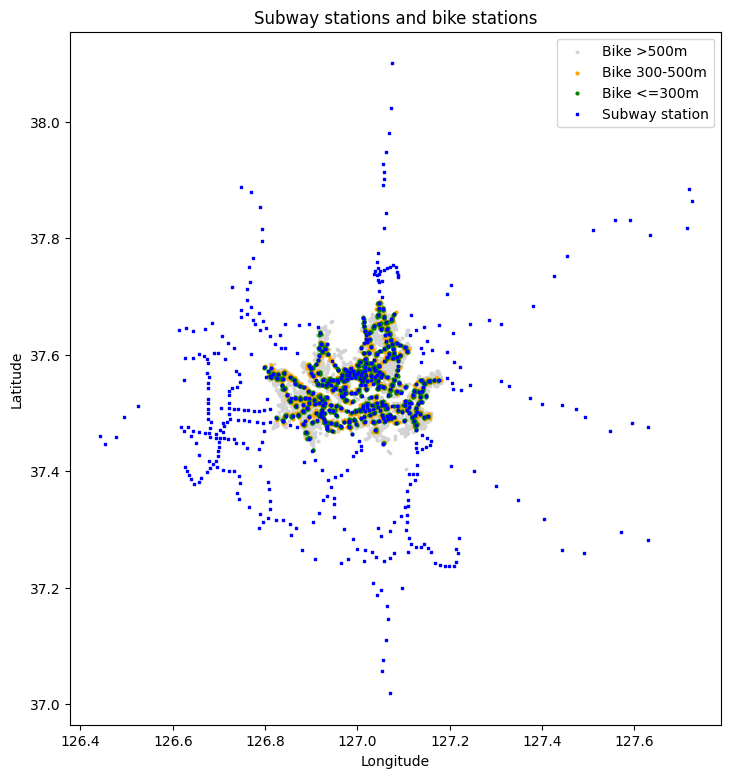

In [33]:
# =========================================================
# [검증 2] 배경지도 없는 위치 확인 — matplotlib 산점도
#  - 타일 서버를 쓰지 않으므로 API 키 문제와 무관하게 항상 표시됨
#  - 한글 폰트 문제를 피하려고 범례는 영어로 표기
# =========================================================
import matplotlib.pyplot as plt

d = bike_nearest_subway["nearest_distance_m"]
fig, ax = plt.subplots(figsize=(10, 9))

# 대여소: 최근접역 거리로 색 구분
ax.scatter(bike_nearest_subway.loc[d > 500, "longitude"],
           bike_nearest_subway.loc[d > 500, "latitude"],
           s=3, c="lightgray", label="Bike >500m")
ax.scatter(bike_nearest_subway.loc[(d > 300) & (d <= 500), "longitude"],
           bike_nearest_subway.loc[(d > 300) & (d <= 500), "latitude"],
           s=4, c="orange", label="Bike 300-500m")
ax.scatter(bike_nearest_subway.loc[d <= 300, "longitude"],
           bike_nearest_subway.loc[d <= 300, "latitude"],
           s=4, c="green", label="Bike <=300m")

# 지하철역
ax.scatter(subway_stations["lon"], subway_stations["lat"],
           s=4, c="blue", marker="s", label="Subway station")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(37.55)))   # 위도 보정 → 서울 모양이 찌그러지지 않게
ax.legend(loc="upper right")
ax.set_title("Subway stations and bike stations")
plt.show()

# 지도로 확인

In [23]:
# =========================================================
# [지도 0] 준비 — folium 설치·불러오기
#  - [지하철 A]~[E]를 실행해 데이터프레임이 메모리에 있어야 함
#  - 런타임을 재시작했다면 저장한 parquet에서 다시 읽어옴
# =========================================================
%pip install -q folium

import os
import html
import folium
import pandas as pd
from IPython.display import display

SUBWAY_OUT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/final_project/data/subway_processed"
)

# 메모리에 없으면 저장 파일에서 불러오기
if "subway_stations" not in globals():
    subway_stations = pd.read_parquet(os.path.join(SUBWAY_OUT_DIR, "subway_stations.parquet"))
    station_subway_link = pd.read_parquet(os.path.join(SUBWAY_OUT_DIR, "station_subway_link.parquet"))
    bike_nearest_subway = pd.read_parquet(os.path.join(SUBWAY_OUT_DIR, "bike_nearest_subway.parquet"))

MAX_LINK_RADIUS_M = 500
NEAR_RADIUS_M = 300

In [25]:
# =========================================================
# [지도 1] 서울 전체 보기
#  - 파란 점 : 지하철역(물리역, 환승역은 1개로 묶음)
#  - 초록 점 : 역 300m 안 대여소
#  - 주황 점 : 역 300~500m 대여소
#  - 회색 점 : 역 500m 밖 대여소
#  - prefer_canvas=True → 수천 개 점도 가볍게 표시
#  - 오른쪽 위 레이어 버튼으로 종류별 켜기/끄기
# =========================================================
m_all = folium.Map(
    location=[37.5665, 126.9780],   # 서울시청 중심
    zoom_start=11,
    # tiles="OpenStreetMap",  #403오류발생
    tiles="cartodbpositron",
    prefer_canvas=True,
)

# 대여소를 가장 가까운 역까지 거리로 3구간 분류
def distance_group(d):
    if d <= NEAR_RADIUS_M:
        return "near"
    if d <= MAX_LINK_RADIUS_M:
        return "mid"
    return "far"

bike_view = bike_nearest_subway.assign(
    group=bike_nearest_subway["nearest_distance_m"].map(distance_group)
)

layer_style = {
    "near": (f"대여소: 역 {NEAR_RADIUS_M}m 안", "green"),
    "mid":  (f"대여소: 역 {NEAR_RADIUS_M}~{MAX_LINK_RADIUS_M}m", "orange"),
    "far":  (f"대여소: 역 {MAX_LINK_RADIUS_M}m 밖", "gray"),
}

# --- 대여소 레이어 3개 ---
for group, (layer_name, color) in layer_style.items():
    layer = folium.FeatureGroup(name=layer_name, show=(group != "far"))
    for row in bike_view[bike_view["group"] == group].itertuples():
        folium.CircleMarker(
            [row.latitude, row.longitude],
            radius=2.5,
            color=color,
            fill=True,
            fill_opacity=0.8,
            weight=0,
            tooltip=html.escape(
                f"{row.station_name} | 가까운 역: {row.nearest_subway_name} "
                f"({row.nearest_distance_m:,.0f}m)"
            ),
        ).add_to(layer)
    layer.add_to(m_all)

# --- 지하철역 레이어 ---
subway_layer = folium.FeatureGroup(name="지하철역")
for row in subway_stations.itertuples():
    folium.CircleMarker(
        [row.lat, row.lon],
        radius=4,
        color="blue",
        fill=True,
        fill_opacity=0.9,
        tooltip=html.escape(f"{row.subway_name} ({row.lines})"),
    ).add_to(subway_layer)
subway_layer.add_to(m_all)

folium.LayerControl(collapsed=False).add_to(m_all)

# 노트북에 표시 + HTML로 저장 (Drive에서 브라우저로 열어볼 수 있음)
display(m_all)
m_all.save(os.path.join(SUBWAY_OUT_DIR, "map_subway_bike_all.html"))

Output hidden; open in https://colab.research.google.com to view.

In [26]:
# =========================================================
# [지도 2] 특정 역 확대 보기 — 반경 원 + 근처 대여소 + 연결선
#  - TARGET_SUBWAY에 역명을 입력 (예: "강남", "여의도", "합정")
#  - 같은 이름이 여러 개면(동명이역) 후보를 출력하고 첫 번째를 사용
# =========================================================
TARGET_SUBWAY = "합정"

# --- 대상 역 찾기 ---
candidates = subway_stations[subway_stations["subway_name"].str.contains(TARGET_SUBWAY, na=False)]
if candidates.empty:
    raise ValueError(f"'{TARGET_SUBWAY}' 역을 찾지 못했습니다.")
if len(candidates) > 1:
    print("후보 역:")
    display(candidates[["phys_key", "subway_name", "lines"]])

target = candidates.iloc[0]
links = station_subway_link[station_subway_link["phys_key"] == target["phys_key"]]
print(f"{target['subway_name']} ({target['lines']}) — 반경 {MAX_LINK_RADIUS_M}m 안 대여소 {len(links)}곳")

m_one = folium.Map(location=[target["lat"], target["lon"]], zoom_start=16,tiles="cartodbpositron",)

# --- 반경 원 (300m, 500m) ---
for radius, color in [(NEAR_RADIUS_M, "green"), (MAX_LINK_RADIUS_M, "orange")]:
    folium.Circle(
        [target["lat"], target["lon"]],
        radius=radius,
        color=color,
        fill=False,
        weight=2,
        tooltip=f"반경 {radius}m",
    ).add_to(m_one)

# --- 지하철역 마커 ---
folium.Marker(
    [target["lat"], target["lon"]],
    tooltip=html.escape(f"{target['subway_name']} ({target['lines']})"),
    icon=folium.Icon(color="blue", icon="train", prefix="fa"),
).add_to(m_one)

# --- 근처 대여소 + 역까지 연결선 ---
bike_xy = bike_nearest_subway.set_index("station_id")[["latitude", "longitude"]]
for row in links.itertuples():
    lat, lon = bike_xy.loc[row.station_id]
    color = "green" if row.distance_m <= NEAR_RADIUS_M else "orange"
    label = html.escape(
        f"{row.station_name} | {row.distance_m:,.0f}m"
        + (" | 이 대여소의 가장 가까운 역" if row.is_nearest else " | 더 가까운 역이 따로 있음")
    )
    folium.CircleMarker(
        [lat, lon], radius=6, color=color, fill=True, fill_opacity=0.9, tooltip=label,
    ).add_to(m_one)
    folium.PolyLine(
        [[lat, lon], [target["lat"], target["lon"]]],
        color=color, weight=2, opacity=0.6,
        dash_array=None if row.is_nearest else "5,5",   # 점선 = 다른 역이 더 가까움
    ).add_to(m_one)

display(m_one)
display(links[["station_name", "distance_m", "radius_band", "is_nearest"]])

합정 (2호선, 6호선) — 반경 500m 안 대여소 5곳


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


,station_name,distance_m,radius_band,is_nearest
2185,합정역 7번출구 앞,101.7,0-300m,True
2186,합정역 5번출구 앞,132.4,0-300m,True
2187,합정역 1번출구 앞,204.7,0-300m,True
2188,합정동주민센터 앞,292.1,0-300m,True
2189,시석빌딩 앞,296.2,0-300m,True


# 삭제삭제_ 제대로 가져오는지 확인용,

In [4]:
import pandas as pd

# parquet 파일 읽기
df = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/final_project/data/bike_raw/trip_2021-05-06.parquet")

# 확인
# print(df.head())
# print(df.shape)
# print(df.info())
df.head()

,BIKE_ID,RENT_DT,RENT_ID,RENT_NM,RENT_HOLD,RTN_DT,RTN_ID,RTN_NM,RTN_HOLD,USE_MIN,USE_DST,USR_CLS_CD,SEX_CD,BIRTH_YEAR,RENT_STATION_ID,RETURN_STATION_ID,BIKE_SE_CD,START_INDEX,END_INDEX,RNUM
0,SPB-33265,2021-05-06 00:00:21,00838,숙대입구역 4번출구,0,2021-05-06 00:00:32,00838,숙대입구역 4번출구,0,0,0.00,USR_001,M,1969,ST-1376,ST-1376,일반자전거,0,0,1
1,SPB-40063,2021-05-06 00:00:31,02540,반포천 앞,0,2021-05-06 00:00:41,02540,반포천 앞,0,0,0.00,USR_001,None,1993,ST-1924,ST-1924,일반자전거,0,0,2
2,SPB-81064,2021-05-06 00:00:14,00240,문래역 4번출구 앞,99,2021-05-06 00:00:58,00240,문래역 4번출구 앞,99,0,30.00,USR_001,None,1991,ST-289,ST-289,새싹자전거,0,0,3
3,SPB-53020,2021-05-06 00:01:56,02050,노량진역 5번출구,0,2021-05-06 00:02:13,02050,노량진역 5번출구,0,0,88.20,USR_001,M,1988,ST-699,ST-699,일반자전거,0,0,4
4,SPB-55035,2021-05-06 00:00:46,00765,오목교역 3번출구,0,2021-05-06 00:02:21,00762,오목로 무중력지대 앞,0,1,180.00,USR_001,M,1998,ST-1731,ST-1503,일반자전거,0,0,5
